# A/B Test Analysis — Credit Scoring Model

## Часть 1: Импорт, загрузка данных и EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

# Настройка стиля графиков
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

## 2. Загрузка данных

In [ ]:
# Чтение трёх выборок
historical = pd.read_csv('../data/historical.csv')
control = pd.read_csv('../data/control.csv')
treatment = pd.read_csv('../data/treatment.csv')

print(f"Historical: {historical.shape[0]:,} строк")
print(f"Control: {control.shape[0]:,} строк")
print(f"Treatment: {treatment.shape[0]:,} строк")

Historical: 50,000 строк
Control: 15,834 строк
Treatment: 15,839 строк


## 3. Разведочный анализ данных (EDA)

### 3.1. Общая информация

In [ ]:
# Информация о датасетах
print("=" * 60)
print("HISTORICAL")
print("=" * 60)
print(historical.info())
print()

print("=" * 60)
print("CONTROL")
print("=" * 60)
print(control.info())
print()

print("=" * 60)
print("TREATMENT")
print("=" * 60)
print(treatment.info())

HISTORICAL
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   account_rk                15299 non-null  float64
 1   financial_application_rk  50000 non-null  int64  
 2   application_date          50000 non-null  str    
 3   PD                        50000 non-null  float64
 4   income_model              50000 non-null  float64
 5   limit                     50000 non-null  float64
 6   NPV_appl                  50000 non-null  float64
 7   approve_flg               50000 non-null  int64  
 8   fraud_flg                 50000 non-null  int64  
 9   d2p4                      50000 non-null  int64  
 10  take_flg                  50000 non-null  int64  
 11  age                       50000 non-null  int64  
 12  region_id                 50000 non-null  int64  
 13  gender                    50000 non-null  str    
 14  active

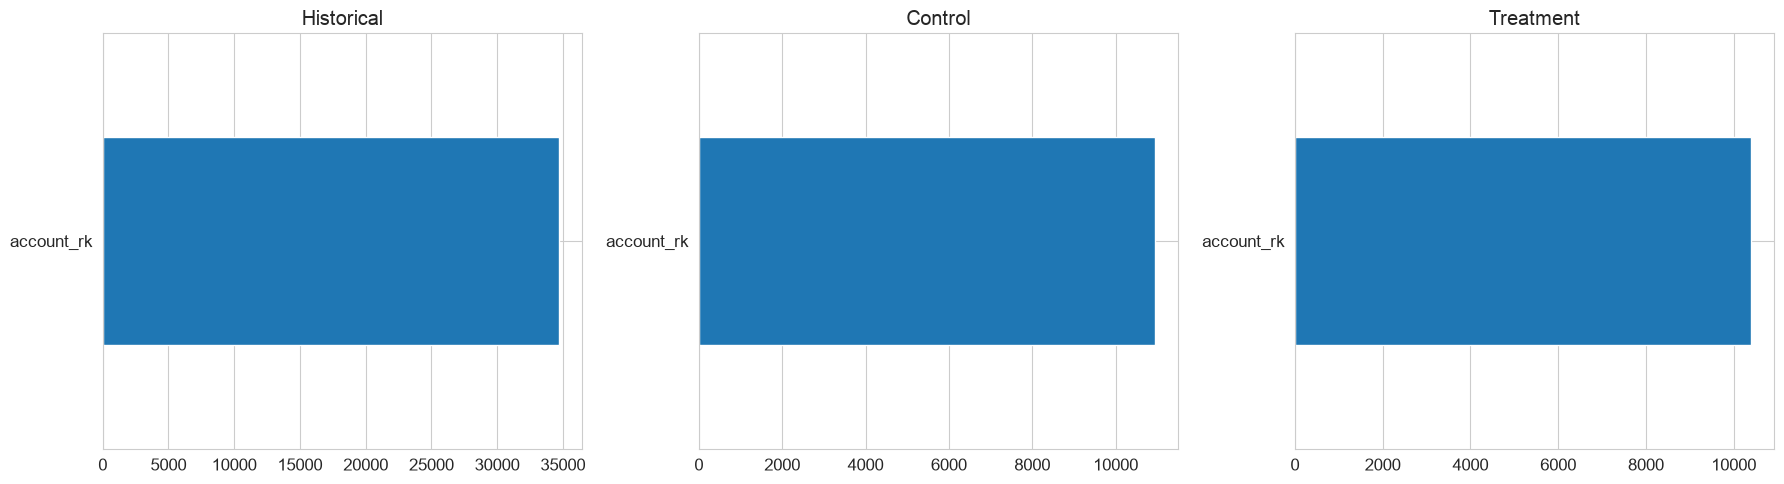

Пропуски в каждом датасете:
Historical: 34701
Control: 10946
Treatment: 10398


In [ ]:
# Проверка пропусков
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (df, title) in enumerate(zip(
    [historical, control, treatment],
    ['Historical', 'Control', 'Treatment']
)):
    missing = df.isnull().sum()
    missing = missing[missing > 0]
    if len(missing) > 0:
        missing.plot(kind='barh', ax=axes[idx], title=title)
    else:
        axes[idx].text(0.5, 0.5, 'No missing values', ha='center', va='center', transform=axes[idx].transAxes)
        axes[idx].set_xlim(0, 1)
        axes[idx].set_ylim(0, 1)

plt.tight_layout()
plt.show()

print("Пропуски в каждом датасете:")
print(f"Historical: {historical.isnull().sum().sum()}")
print(f"Control: {control.isnull().sum().sum()}")
print(f"Treatment: {treatment.isnull().sum().sum()}")

### 3.2. Сравнение распределений ключевых метрик

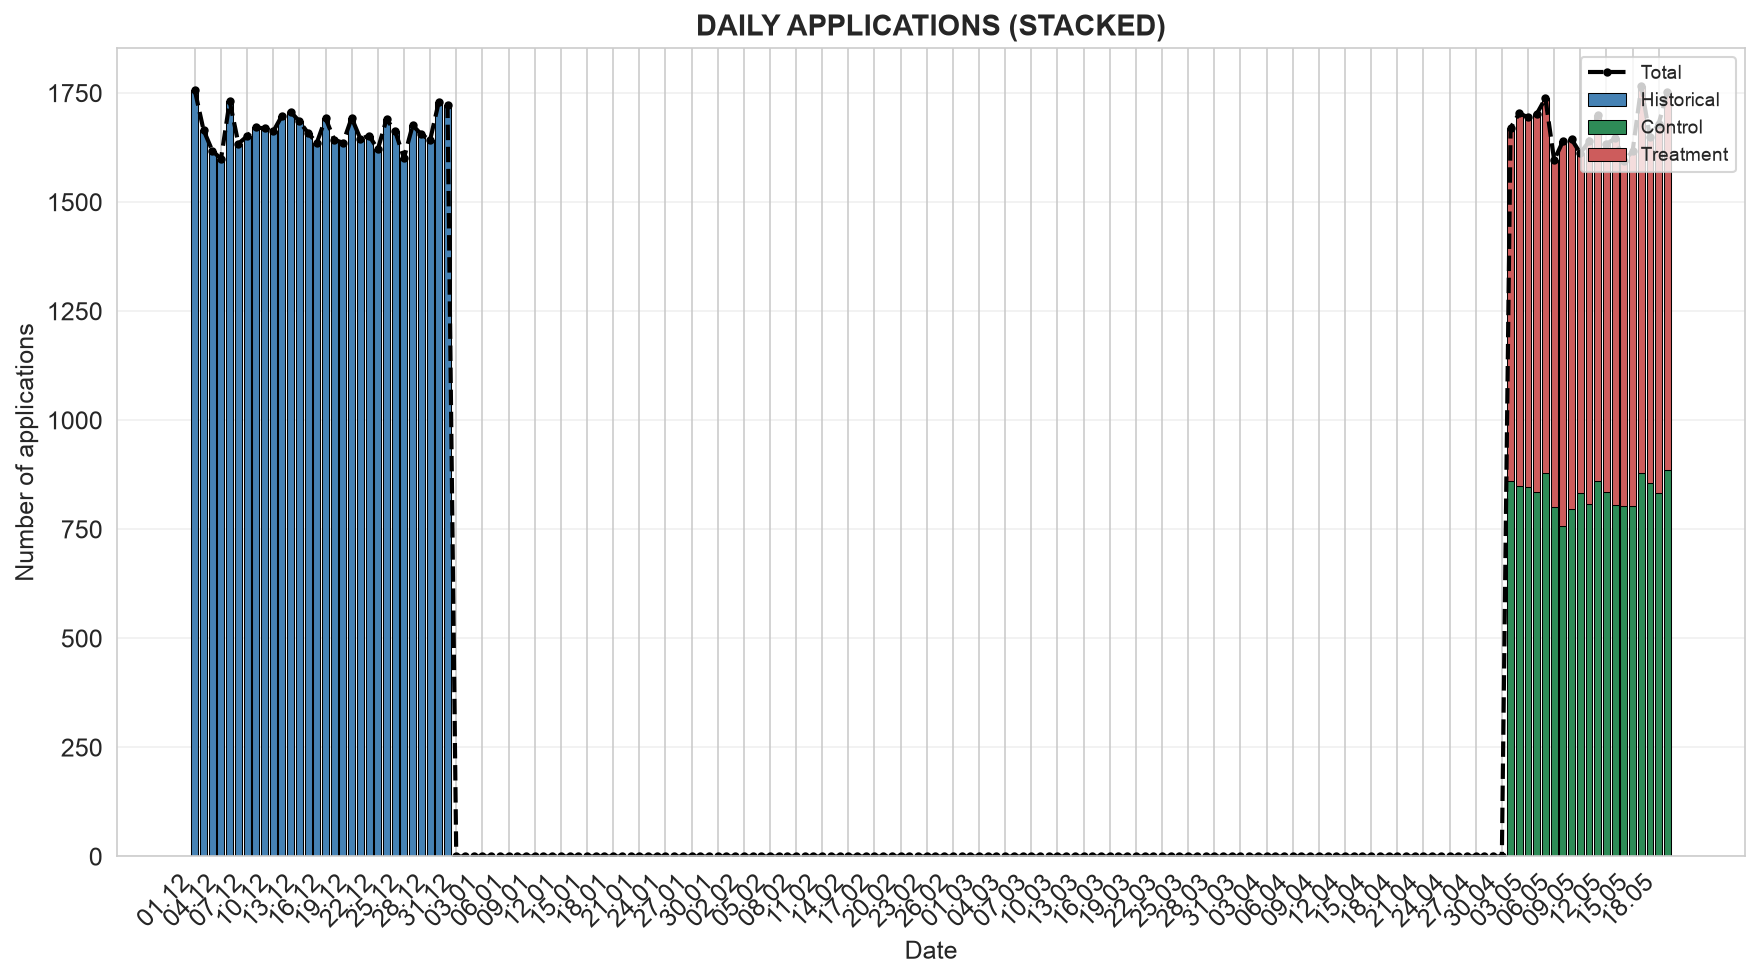

In [ ]:
# Анализ распределения заявок по дням (стекированные гистограммы)
import matplotlib.dates as mdates

# Преобразуем даты
historical['application_date'] = pd.to_datetime(historical['application_date'])
control['application_date'] = pd.to_datetime(control['application_date'])
treatment['application_date'] = pd.to_datetime(treatment['application_date'])

# Группируем по дням
daily_historical = historical.groupby(historical['application_date'].dt.normalize()).size()
daily_control = control.groupby(control['application_date'].dt.normalize()).size()
daily_treatment = treatment.groupby(treatment['application_date'].dt.normalize()).size()

# Создаём общий диапазон дат
all_dates = pd.date_range(
    start=min(daily_historical.index.min(), daily_control.index.min(), daily_treatment.index.min()),
    end=max(daily_historical.index.max(), daily_control.index.max(), daily_treatment.index.max())
)

# Реиндексируем, заполняя нулями пропуски
daily_historical = daily_historical.reindex(all_dates, fill_value=0)
daily_control = daily_control.reindex(all_dates, fill_value=0)
daily_treatment = daily_treatment.reindex(all_dates, fill_value=0)

# Создаём фигуру
fig, axes = plt.subplots(1, 1, figsize=(14, 7), dpi=150)

# 1. Стекированная гистограмма по дням
ax = axes

dates = daily_historical.index
x = np.arange(len(dates))

ax.bar(x, daily_historical.values, label='Historical', color='steelblue', edgecolor='black', linewidth=0.5)
ax.bar(x, daily_control.values, bottom=daily_historical.values, 
       label='Control', color='seagreen', edgecolor='black', linewidth=0.5)
ax.bar(x, daily_treatment.values, 
       bottom=daily_historical.values + daily_control.values, 
       label='Treatment', color='indianred', edgecolor='black', linewidth=0.5)

# Линия общего итога
ax.plot(x, daily_historical.values + daily_control.values + daily_treatment.values, 
        color='black', linewidth=2, linestyle='--', label='Total', marker='o', markersize=3)

ax.set_title('DAILY APPLICATIONS (STACKED)', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Number of applications')
ax.legend(loc='upper right', fontsize=9)
ax.grid(True, alpha=0.3, axis='y')

# Форматирование дат
ax.set_xticks(x[::3])
ax.set_xticklabels([d.strftime('%d.%m') for d in dates[::3]], rotation=45, ha='right');
plt.show()

### 3.3. Визуализация распределений NPV_fact

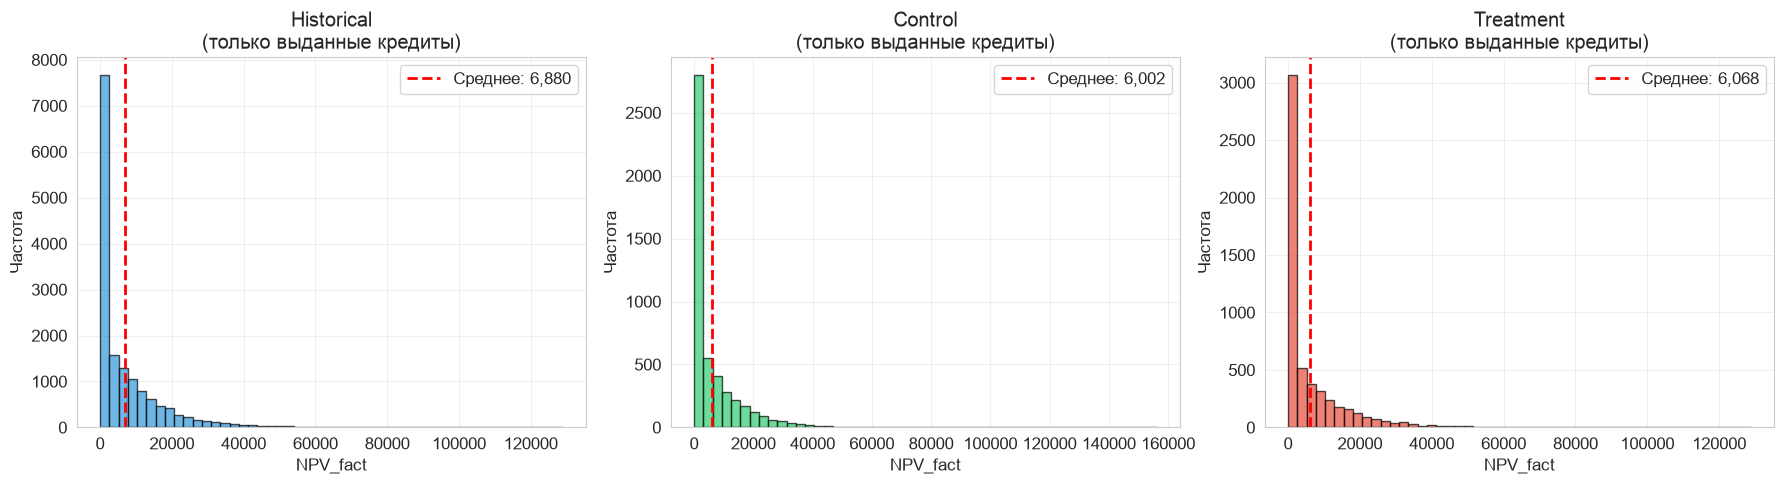

In [ ]:
# Гистограммы распределения NPV_fact по трём группам
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (df, title, color) in enumerate(zip(
    [historical[historical['take_flg'] == 1], 
     control[control['take_flg'] == 1], 
     treatment[treatment['take_flg'] == 1]],
    ['Historical', 'Control', 'Treatment'],
    ['#3498db', '#2ecc71', '#e74c3c']
)):
    axes[idx].hist(df['NPV_fact'], bins=50, color=color, alpha=0.7, edgecolor='black')
    axes[idx].axvline(df['NPV_fact'].mean(), color='red', linestyle='--', linewidth=2, 
                      label=f"Среднее: {df['NPV_fact'].mean():,.0f}")
    axes[idx].set_xlabel('NPV_fact')
    axes[idx].set_ylabel('Частота')
    axes[idx].set_title(f'{title}\n(только выданные кредиты)')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

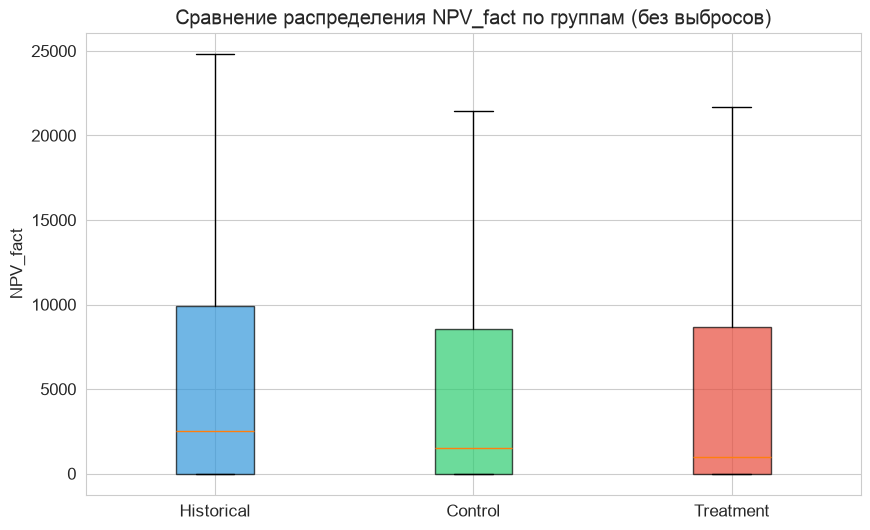

In [ ]:
# Boxplot для сравнения распределений NPV
fig, ax = plt.subplots(figsize=(10, 6))

data_to_plot = [
    historical[historical['take_flg'] == 1]['NPV_fact'],
    control[control['take_flg'] == 1]['NPV_fact'],
    treatment[treatment['take_flg'] == 1]['NPV_fact']
]

bp = ax.boxplot(data_to_plot, patch_artist=True, showfliers=False)
ax.set_xticklabels(['Historical', 'Control', 'Treatment'])

colors = ['#3498db', '#2ecc71', '#e74c3c']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_ylabel('NPV_fact')
ax.set_title('Сравнение распределения NPV_fact по группам (без выбросов)')
plt.show()

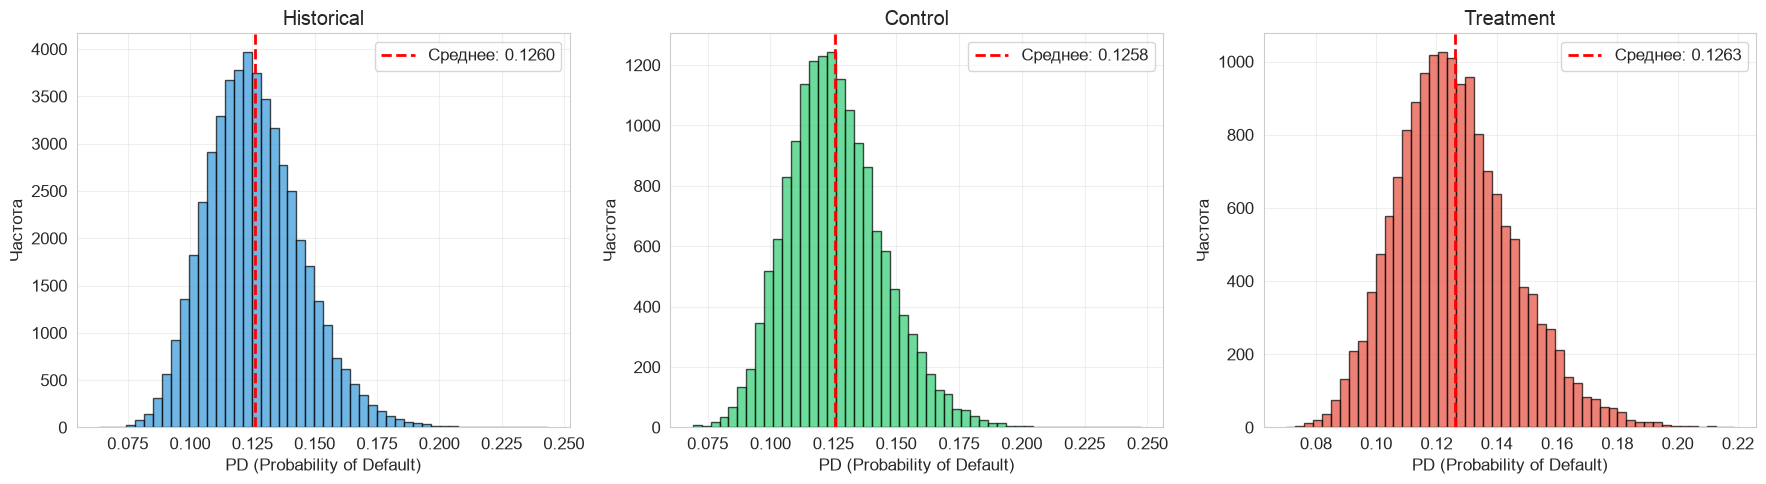

Статистика PD:
Historical: mean=0.1260, std=0.0190, median=0.1245
Control: mean=0.1258, std=0.0190, median=0.1242
Treatment: mean=0.1263, std=0.0193, median=0.1247


In [ ]:
# Распределение PD
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (df, title, color) in enumerate(zip(
    [historical, control, treatment],
    ['Historical', 'Control', 'Treatment'],
    ['#3498db', '#2ecc71', '#e74c3c']
)):
    axes[idx].hist(df['PD'], bins=50, color=color, alpha=0.7, edgecolor='black')
    axes[idx].axvline(df['PD'].mean(), color='red', linestyle='--', linewidth=2, 
                      label=f"Среднее: {df['PD'].mean():.4f}")
    axes[idx].set_xlabel('PD (Probability of Default)')
    axes[idx].set_ylabel('Частота')
    axes[idx].set_title(f'{title}')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Статистика PD:")
for name, df in [('Historical', historical), ('Control', control), ('Treatment', treatment)]:
    print(f"{name}: mean={df['PD'].mean():.4f}, std={df['PD'].std():.4f}, median={df['PD'].median():.4f}")

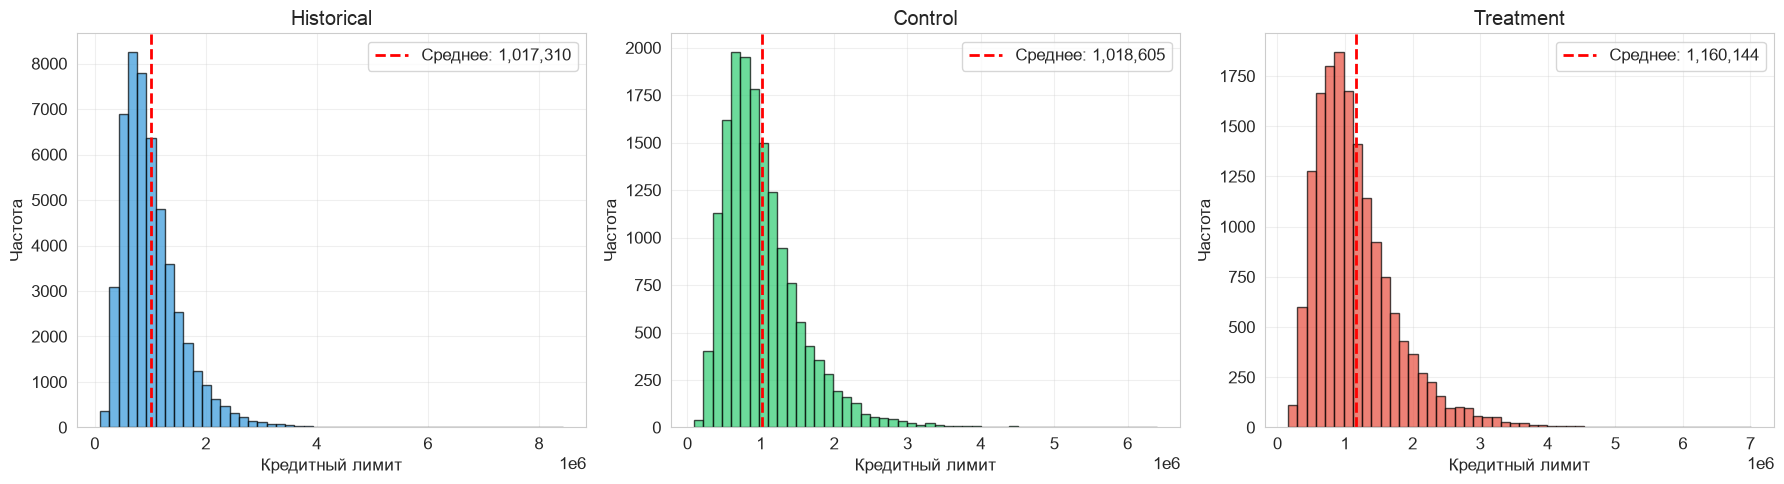

In [ ]:
# Распределение кредитных лимитов
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (df, title, color) in enumerate(zip(
    [historical, control, treatment],
    ['Historical', 'Control', 'Treatment'],
    ['#3498db', '#2ecc71', '#e74c3c']
)):
    axes[idx].hist(df['limit'], bins=50, color=color, alpha=0.7, edgecolor='black')
    axes[idx].axvline(df['limit'].mean(), color='red', linestyle='--', linewidth=2, 
                      label=f"Среднее: {df['limit'].mean():,.0f}")
    axes[idx].set_xlabel('Кредитный лимит')
    axes[idx].set_ylabel('Частота')
    axes[idx].set_title(f'{title}')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Проверка однородности групп по фичам клиентов

Проверим, что контрольная и тестовая группы однородны (сбалансированы) по основным характеристикам клиентов.

### 4.1. Список фичей для проверки

In [ ]:
# Определяем фичи для проверки баланса
continuous_features = ['age', 'active_loans_count']
categorical_features = ['region_id', 'gender']

print("=" * 80)
print("ПРОВЕРКА ОДНОРОДНОСТИ ГРУПП ПО ФИЧАМ КЛИЕНТОВ")
print("=" * 80)
print(f"\nНепрерывные фичи: {continuous_features}")
print(f"Категориальные фичи: {categorical_features}")

ПРОВЕРКА ОДНОРОДНОСТИ ГРУПП ПО ФИЧАМ КЛИЕНТОВ

Непрерывные фичи: ['age', 'active_loans_count']
Категориальные фичи: ['region_id', 'gender']


### 4.2. Проверка непрерывных фичей

Для непрерывных фичей используем t-тест Стьюдента для сравнения средних.


4.2. НЕПРЕРЫВНЫЕ ФИЧИ (t-тест)

age:
  Control:     35.16
  Treatment:   35.21
  Разница:     +0.05 (+0.13%)
  t-stat:      -0.5832
  p-value:     0.5598 ✓ OK

active_loans_count:
  Control:     1.48
  Treatment:   1.49
  Разница:     +0.00 (+0.21%)
  t-stat:      -0.2274
  p-value:     0.8201 ✓ OK



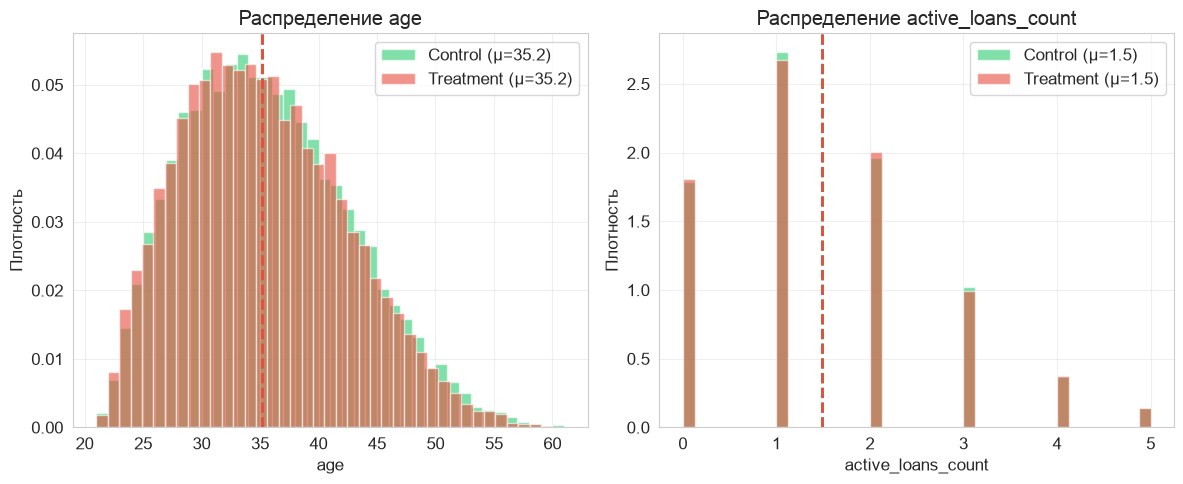

SUMMARY: НЕПРЕРЫВНЫЕ ФИЧИ
✅ Все непрерывные фичи сбалансированы (p >= 0.05)


In [ ]:
print("\n" + "=" * 80)
print("4.2. НЕПРЕРЫВНЫЕ ФИЧИ (t-тест)")
print("=" * 80)
print()

continuous_results = []

for feature in continuous_features:
    ctrl_data = control[feature].dropna()
    trt_data = treatment[feature].dropna()
    
    # T-тест
    t_stat, p_value = stats.ttest_ind(ctrl_data, trt_data, equal_var=False)
    
    # Разница средних
    ctrl_mean = ctrl_data.mean()
    trt_mean = trt_data.mean()
    diff = trt_mean - ctrl_mean
    diff_pct = (diff / ctrl_mean) * 100 if ctrl_mean != 0 else 0
    
    continuous_results.append({
        'feature': feature,
        'control_mean': ctrl_mean,
        'treatment_mean': trt_mean,
        'diff': diff,
        'diff_pct': diff_pct,
        't_stat': t_stat,
        'p_value': p_value,
        'significant': p_value < 0.05
    })
    
    status = "⚠️ ЗНАЧИМО" if p_value < 0.05 else "✓ OK"
    print(f"{feature}:")
    print(f"  Control:     {ctrl_mean:,.2f}")
    print(f"  Treatment:   {trt_mean:,.2f}")
    print(f"  Разница:     {diff:+,.2f} ({diff_pct:+.2f}%)")
    print(f"  t-stat:      {t_stat:.4f}")
    print(f"  p-value:     {p_value:.4f} {status}")
    print()

# Визуализация непрерывных фичей
fig, axes = plt.subplots(1, len(continuous_features), figsize=(6 * len(continuous_features), 5))

if len(continuous_features) == 1:
    axes = [axes]

colors = {'Control': '#2ecc71', 'Treatment': '#e74c3c'}

for idx, feature in enumerate(continuous_features):
    ax = axes[idx]
    
    # Гистограммы
    ax.hist(control[feature], bins=40, alpha=0.6, color=colors['Control'], 
            label=f"Control (μ={control[feature].mean():.1f})", density=True)
    ax.hist(treatment[feature], bins=40, alpha=0.6, color=colors['Treatment'], 
            label=f"Treatment (μ={treatment[feature].mean():.1f})", density=True)
    
    # Линии средних
    ax.axvline(control[feature].mean(), color=colors['Control'], linestyle='--', linewidth=2)
    ax.axvline(treatment[feature].mean(), color=colors['Treatment'], linestyle='--', linewidth=2)
    
    ax.set_xlabel(feature)
    ax.set_ylabel('Плотность')
    ax.set_title(f'Распределение {feature}')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Summary по непрерывным фичам
print("=" * 80)
print("SUMMARY: НЕПРЕРЫВНЫЕ ФИЧИ")
print("=" * 80)

significant_continuous = [r for r in continuous_results if r['significant']]
if len(significant_continuous) == 0:
    print("✅ Все непрерывные фичи сбалансированы (p >= 0.05)")
else:
    print(f"⚠️ {len(significant_continuous)} фич(и) с значимыми различиями:")
    for r in significant_continuous:
        print(f"   - {r['feature']}: p={r['p_value']:.4f}, разница {r['diff_pct']:+.2f}%")

### 4.3. Проверка категориальных фичей

Для категориальных фичей используем хи-квадрат тест Пирсона.


4.3. КАТЕГОРИАЛЬНЫЕ ФИЧИ (хи-квадрат тест)

region_id:
  Хи-квадрат:  38.9757
  Степени свободы: 49
  p-value:     0.8468 ✓ OK
  Макс. разница долей: 0.84%

gender:
  Хи-квадрат:  0.0435
  Степени свободы: 1
  p-value:     0.8348 ✓ OK
  Макс. разница долей: 0.12%



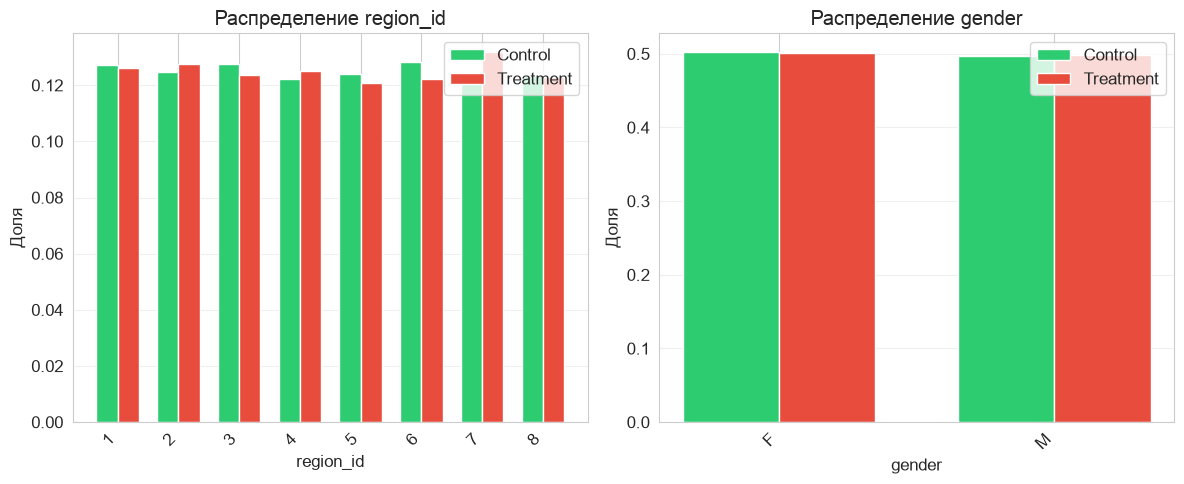

SUMMARY: КАТЕГОРИАЛЬНЫЕ ФИЧИ
✅ Все категориальные фичи сбалансированы (p >= 0.05)


In [ ]:
print("\n" + "=" * 80)
print("4.3. КАТЕГОРИАЛЬНЫЕ ФИЧИ (хи-квадрат тест)")
print("=" * 80)
print()

categorical_results = []

for feature in categorical_features:
    # Создаём таблицу сопряжённости
    contingency_table = pd.crosstab(control[feature], treatment[feature])
    
    # Хи-квадрат тест
    chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table)
    
    # Распределения по категориям
    ctrl_dist = control[feature].value_counts(normalize=True).sort_index()
    trt_dist = treatment[feature].value_counts(normalize=True).sort_index()
    
    # Максимальная разница в долях
    max_diff = abs(ctrl_dist - trt_dist).max() * 100
    
    categorical_results.append({
        'feature': feature,
        'chi2': chi2,
        'p_value': p_value,
        'dof': dof,
        'max_diff_pct': max_diff,
        'significant': p_value < 0.05
    })
    
    status = "⚠️ ЗНАЧИМО" if p_value < 0.05 else "✓ OK"
    print(f"{feature}:")
    print(f"  Хи-квадрат:  {chi2:.4f}")
    print(f"  Степени свободы: {dof}")
    print(f"  p-value:     {p_value:.4f} {status}")
    print(f"  Макс. разница долей: {max_diff:.2f}%")
    print()

# Визуализация категориальных фичей
n_cat = len(categorical_features)
fig, axes = plt.subplots(1, n_cat, figsize=(6 * n_cat, 5))

if n_cat == 1:
    axes = [axes]

for idx, feature in enumerate(categorical_features):
    ax = axes[idx]
    
    # Подсчёт долей
    ctrl_counts = control[feature].value_counts(normalize=True).sort_index()
    trt_counts = treatment[feature].value_counts(normalize=True).sort_index()
    
    # Объединяем категории
    all_categories = sorted(set(ctrl_counts.index) | set(trt_counts.index))
    
    x = np.arange(len(all_categories))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, [ctrl_counts.get(cat, 0) for cat in all_categories], 
                   width, label='Control', color=colors['Control'])
    bars2 = ax.bar(x + width/2, [trt_counts.get(cat, 0) for cat in all_categories], 
                   width, label='Treatment', color=colors['Treatment'])
    
    ax.set_xlabel(feature)
    ax.set_ylabel('Доля')
    ax.set_title(f'Распределение {feature}')
    ax.set_xticks(x)
    ax.set_xticklabels(all_categories, rotation=45, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Summary по категориальным фичам
print("=" * 80)
print("SUMMARY: КАТЕГОРИАЛЬНЫЕ ФИЧИ")
print("=" * 80)

significant_categorical = [r for r in categorical_results if r['significant']]
if len(significant_categorical) == 0:
    print("✅ Все категориальные фичи сбалансированы (p >= 0.05)")
else:
    print(f"⚠️ {len(significant_categorical)} фич(и) с значимыми различиями:")
    for r in significant_categorical:
        print(f"   - {r['feature']}: p={r['p_value']:.4f}, макс. разница {r['max_diff_pct']:.2f}%")

## 5. Статистический анализ основных метрик

Проверим статистическую значимость различий между Control и Treatment группами по ключевым метрикам.

### 5.1. NPV_fact (основная метрика)

**Гипотезы:**
- H₀: Средний NPV в Treatment ≤ Среднего NPV в Control (нет улучшения)
- H₁: Средний NPV в Treatment > Среднего NPV в Control (есть улучшение)

**Метод:** Двухвыборочный t-тест Стьюдента

In [ ]:
from scipy.stats import ttest_ind

print("=" * 80)
print("5. СТАТИСТИЧЕСКИЙ АНАЛИЗ ОСНОВНЫХ МЕТОДИК")
print("=" * 80)
print()

# --- NPV_fact ---
control_npv = control["NPV_fact"]
treatment_npv = treatment["NPV_fact"]

t_stat, p_value_two_sided = ttest_ind(
    treatment_npv, control_npv, equal_var=False, alternative="greater"
)

diff_abs = treatment_npv.mean() - control_npv.mean()
diff_pct = (diff_abs / control_npv.mean()) * 100 if control_npv.mean() != 0 else 0

print("5.1. NPV_fact (основная метрика)")
print("-" * 60)
print(f"  Control:   n={len(control_npv):,}, mean={control_npv.mean():,.0f}, std={control_npv.std():,.0f}")
print(f"  Treatment: n={len(treatment_npv):,}, mean={treatment_npv.mean():,.0f}, std={treatment_npv.std():,.0f}")
print()
print(f"  Разница средних: {diff_abs:+,.0f} ({diff_pct:+.2f}%)")
print(f"  t-statistic:     {t_stat:.4f}")
print(f"  p-value (one-sided): {p_value:.4f}")
print()

if p_value < 0.05:
    print("  ✅ СТАТИСТИЧЕСКИ ЗНАЧИМОЕ УЛУЧШЕНИЕ (p < 0.05)")
    print("     Отклоняем H₀ — новая модель улучшает NPV")
else:
    print("  ❌ НЕТ ЗНАЧИМОГО УЛУЧШЕНИЯ (p >= 0.05)")
    print("     Не отклоняем H₀ — улучшение не доказано")

5. СТАТИСТИЧЕСКИЙ АНАЛИЗ ОСНОВНЫХ МЕТОДИК

5.1. NPV_fact (основная метрика)
------------------------------------------------------------
  Control:   n=15,834, mean=1,853, std=6,086
  Treatment: n=15,839, mean=2,085, std=6,617

  Разница средних: +232 (+12.51%)
  t-statistic:     3.2440
  p-value (one-sided): 0.8348

  ❌ НЕТ ЗНАЧИМОГО УЛУЧШЕНИЯ (p >= 0.05)
     Не отклоняем H₀ — улучшение не доказано


### 5.2. Защитные метрики (fraud_flg, d2p4)

**Гипотезы:**
- H₀: `ratio = treatment_rate / control_rate < 2.0` (рост менее 2x — допустимо)
- H₁: `ratio >= 2.0` (рост в 2+ раза — критичное ухудшение)

**Метод:** Расчёт отношения долей (ratio) + 95% доверительный интервал

In [ ]:
print("=" * 80)
print("5.2. ПРОВЕРКА РОСТА ЗАЩИТНЫХ МЕТРИК")
print("=" * 80)
print()


def check_guard_metric_ratio(control, treatment, metric_name, max_ratio=2.0):
    """
    Проверка: рост метрики в Treatment не должен превышать max_ratio.
    """
    n_ctrl = len(control)
    n_trt = len(treatment)

    rate_ctrl = control.mean()
    rate_trt = treatment.mean()

    ratio = rate_trt / rate_ctrl if rate_ctrl > 0 else float("inf")

    # 95% CI для ratio через логарифмическую трансформацию
    se_log_ratio = (
        np.sqrt(
            (1 - rate_ctrl) / (n_ctrl * rate_ctrl) + (1 - rate_trt) / (n_trt * rate_trt)
        )
        if rate_ctrl > 0 and rate_trt > 0
        else float("inf")
    )

    log_ratio = np.log(ratio) if ratio > 0 else 0
    ci_lower = np.exp(log_ratio - 1.96 * se_log_ratio)
    ci_upper = np.exp(log_ratio + 1.96 * se_log_ratio)

    print(f"Метрика: {metric_name}")
    print(f"  Control:   {rate_ctrl:.2%} (n={n_ctrl:,})")
    print(f"  Treatment: {rate_trt:.2%} (n={n_trt:,})")
    print(f"  Ratio (Trt/Ctrl): {ratio:.2f}x")
    print(f"  95% CI для ratio: [{ci_lower:.2f}x, {ci_upper:.2f}x]")
    print()

    if ci_upper < max_ratio:
        print(f"  ✅ В НОРМЕ: рост статистически значимо < {max_ratio}x")
    elif ratio < max_ratio:
        print(f"  ⚠️ ПО ГРАНИЦЕ: ratio < {max_ratio}x, но CI пересекает границу")
    else:
        print(f"  ❌ КРИТИЧНО: рост >= {max_ratio}x")
    print()

    return ratio, ci_lower, ci_upper


# Проверка для d2p4 и fraud_flg
check_guard_metric_ratio(control["d2p4"], treatment["d2p4"], "d2p4", max_ratio=2.0)
check_guard_metric_ratio(
    control["fraud_flg"], treatment["fraud_flg"], "fraud_flg", max_ratio=2.0
);


5.2. ПРОВЕРКА РОСТА ЗАЩИТНЫХ МЕТРИК

Метрика: d2p4
  Control:   6.97% (n=15,834)
  Treatment: 9.74% (n=15,839)
  Ratio (Trt/Ctrl): 1.40x
  95% CI для ratio: [1.30x, 1.51x]

  ✅ В НОРМЕ: рост статистически значимо < 2.0x

Метрика: fraud_flg
  Control:   0.81% (n=15,834)
  Treatment: 0.77% (n=15,839)
  Ratio (Trt/Ctrl): 0.95x
  95% CI для ratio: [0.74x, 1.21x]

  ✅ В НОРМЕ: рост статистически значимо < 2.0x



## 6. Визуализация распределений

### 6.1. Наложение распределений: Treatment vs Control (NPV_fact, 0 для неутилизованных)

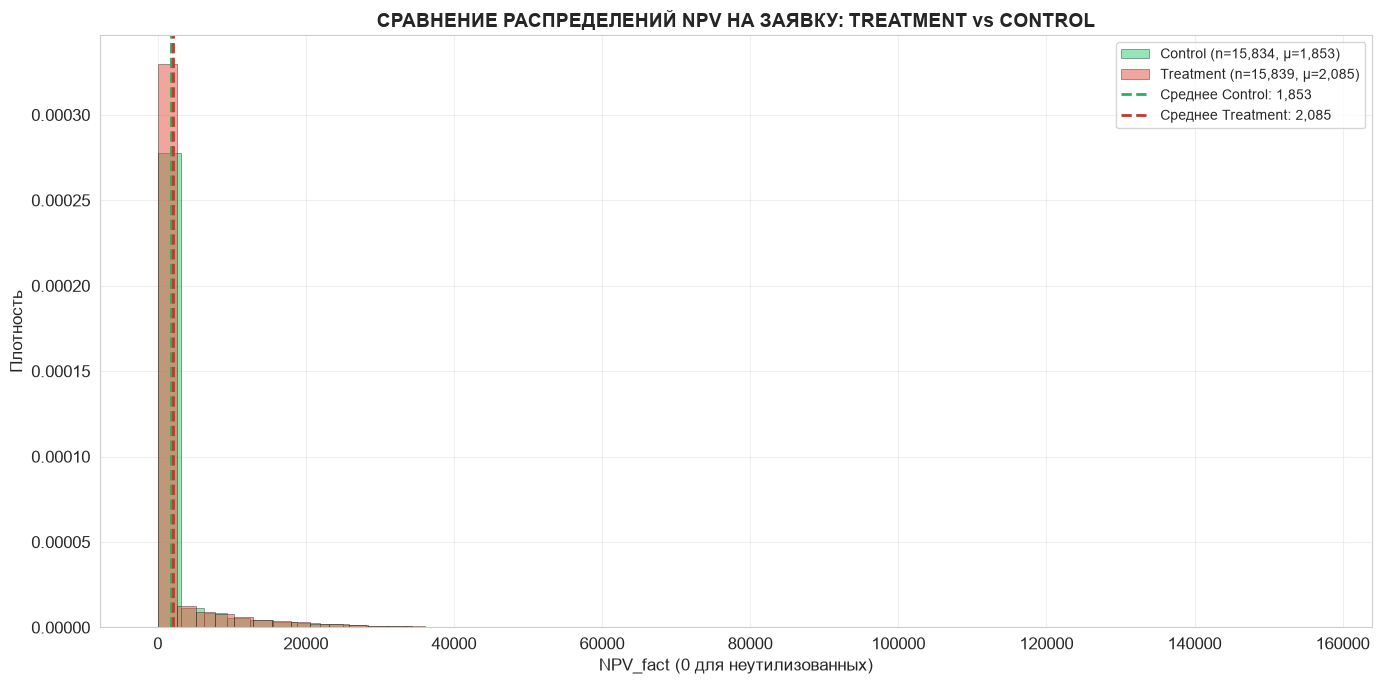

СРАВНЕНИЕ TREATMENT vs CONTROL (NPV_fact)

Разница средних (Treatment - Control): 231.75 (+12.51%)
  Control:   1,852.77 (std=6,085.85)
  Treatment: 2,084.53 (std=6,617.42)


In [ ]:
# Используем NPV_fact для всех заявок: где не было утилизации — ставим 0
control_npv = control['NPV_fact'].fillna(0)
treatment_npv = treatment['NPV_fact'].fillna(0)

fig, ax = plt.subplots(figsize=(14, 7))

# Гистограммы с прозрачностью
ax.hist(control_npv, bins=50, alpha=0.5, color='#2ecc71', 
        label=f'Control (n={len(control_npv):,}, μ={control_npv.mean():,.0f})', 
        density=True, edgecolor='black', linewidth=0.5)

ax.hist(treatment_npv, bins=50, alpha=0.5, color='#e74c3c', 
        label=f'Treatment (n={len(treatment_npv):,}, μ={treatment_npv.mean():,.0f})', 
        density=True, edgecolor='black', linewidth=0.5)



# Линии средних
ax.axvline(control_npv.mean(), color='#27ae60', linestyle='--', linewidth=2, 
           label=f'Среднее Control: {control_npv.mean():,.0f}')
ax.axvline(treatment_npv.mean(), color='#c0392b', linestyle='--', linewidth=2, 
           label=f'Среднее Treatment: {treatment_npv.mean():,.0f}')

ax.set_xlabel('NPV_fact (0 для неутилизованных)', fontsize=12)
ax.set_ylabel('Плотность', fontsize=12)
ax.set_title('СРАВНЕНИЕ РАСПРЕДЕЛЕНИЙ NPV НА ЗАЯВКУ: TREATMENT vs CONTROL', 
             fontsize=14, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Статистика различий
print("=" * 80)
print("СРАВНЕНИЕ TREATMENT vs CONTROL (NPV_fact)")
print("=" * 80)
print()
diff_abs = treatment_npv.mean() - control_npv.mean()
diff_pct = (diff_abs / control_npv.mean()) * 100 if control_npv.mean() != 0 else 0
print(f"Разница средних (Treatment - Control): {diff_abs:,.2f} ({diff_pct:+.2f}%)")
print(f"  Control:   {control_npv.mean():,.2f} (std={control_npv.std():,.2f})")
print(f"  Treatment: {treatment_npv.mean():,.2f} (std={treatment_npv.std():,.2f})")

In [ ]:
ar_baseline = historical['approve_flg'].mean() * 100
print(f"Базовый AR (старая модель): {ar_baseline:.2f}%")

ar_new = treatment['approve_flg_new'].mean() * 100
print(f"Новый AR (новая модель): {ar_new:.2f}%")